# 01 · Ingesta y preparación de datos (Telco Customer Churn)

**TPI – Introducción al Análisis de Datos · UTN Avellaneda · Tecnicatura Universitaria en Programación**

Rol: *Ingesta & Data Prep*. Este notebook toma el CSV original de Kaggle, lo revisa, lo limpia y exporta `data/processed/telco_limpio.csv`, que consumen EDA y Modelado.

**Alcance:** acá NO hacemos EDA visual ni modelado. Los únicos gráficos son los boxplots que pide la consigna para detectar outliers.

| Sección | Contenido |
|---|---|
| 0 | Setup y carga de datos |
| 1 | Problema de negocio e hipótesis |
| 2 | Clasificación del dataset |
| 3 | Relevamiento de variables |
| 4 | Transformación básica |
| 5 | Calidad de datos (nulos ocultos en `total_charges`) y columnas calculadas |
| 6 | Adecuación de tipos de dato |
| 7 | Outliers |
| 8 | Filtrado y agregación |
| 9 | Exportación |
| 10 | Contrato de datos |

> **Nota para quien viene de C#/.NET:** un `DataFrame` de pandas es parecido a un `DataTable`, pero las operaciones se aplican a columnas enteras (vectorizadas) en lugar de recorrer fila por fila con un `foreach`. Los comentarios del código marcan los equivalentes con SQL/LINQ cuando existen.

## 0. Setup y carga de datos

Importamos las librerías del stack del proyecto (pandas, NumPy, Matplotlib, Seaborn).

La carga se hace **desde la URL raw de GitHub del propio repositorio**, así el notebook corre en Google Colab sin subir archivos a mano. Si la URL falla (sin internet, o el CSV todavía no está en la rama `main`), se usa la **ruta local relativa** como plan B. Esto permite que el mismo notebook funcione en la PC de cualquier integrante y en Colab.

In [1]:
import pandas as pd  # pandas: la librería de tablas (DataFrame); es el "LINQ + DataTable" de Python
import numpy as np  # numpy: arrays numéricos y constantes como np.nan (equivale a double.NaN de C#)
import matplotlib.pyplot as plt  # matplotlib: librería base de gráficos (acá solo la usamos para los boxplots)
import seaborn as sns  # seaborn: gráficos estadísticos de más alto nivel, construidos sobre matplotlib
from pathlib import Path  # Path: manejo de rutas de archivos, equivale a System.IO.Path de C#

sns.set_theme(style="whitegrid")  # fija un estilo visual global para todos los gráficos del notebook
pd.set_option("display.max_columns", None)  # evita que pandas oculte columnas con "..." al mostrar tablas anchas
pd.set_option("display.max_colwidth", None)  # evita que pandas corte los textos largos de las celdas
pd.set_option("display.width", 140)  # ancho máximo (en caracteres) al imprimir un DataFrame

In [2]:
GITHUB_USER = "arielzamora"  # CONSTANTE A COMPLETAR: usuario de GitHub dueño del repo (por convención las constantes van en MAYÚSCULAS)
GITHUB_REPO = "tpi-analisis-de-datos"  # nombre del repositorio en GitHub
GITHUB_BRANCH = "main"  # rama de la que se descarga el CSV; "main" lo tiene recién después de mergear el PR
NOMBRE_CSV = "WA_Fn-UseC_-Telco-Customer-Churn.csv"  # nombre exacto del archivo original de Kaggle
URL_RAW = (  # abrimos un paréntesis para poder partir la cadena en varias líneas
    f"https://raw.githubusercontent.com/{GITHUB_USER}/{GITHUB_REPO}/{GITHUB_BRANCH}/data/raw/{NOMBRE_CSV}"  # f-string: interpola {variables}, como $"..." en C#
)  # cierra el paréntesis de la URL
RUTAS_LOCALES = [  # lista de rutas candidatas para el plan B (equivale a una List<Path>)
    Path("../data/raw") / NOMBRE_CSV,  # caso 1: el notebook corre desde notebooks/ (el operador / une partes de una ruta)
    Path("data/raw") / NOMBRE_CSV,  # caso 2: el notebook corre desde la raíz del repo (por ejemplo, Colab con el repo clonado)
]  # cierra la lista


def cargar_telco():  # define una función sin parámetros (en C# sería un método estático que devuelve un DataTable)
    try:  # intenta primero la URL, igual que un bloque try de C#
        df_url = pd.read_csv(URL_RAW)  # read_csv descarga y parsea el CSV directamente desde la URL y arma un DataFrame
        print(f"Cargado desde GitHub (URL raw): {URL_RAW}")  # informa qué fuente se usó
        return df_url  # devuelve el DataFrame y termina la función
    except Exception as error:  # equivale a catch (Exception ex): cubre el 404 (CSV aún no publicado) o la falta de internet
        print(f"No se pudo leer la URL ({type(error).__name__}). Se prueba la ruta local.")  # avisa que se activa el plan B
    for ruta in RUTAS_LOCALES:  # foreach sobre las rutas candidatas
        if ruta.exists():  # equivale a File.Exists(ruta)
            df_local = pd.read_csv(ruta)  # lee el CSV desde el disco
            print(f"Cargado desde archivo local: {ruta.resolve()}")  # muestra la ruta absoluta que se usó
            return df_local  # devuelve el DataFrame y termina la función
    raise FileNotFoundError(f"No se encontró {NOMBRE_CSV} ni en la URL ni en {RUTAS_LOCALES}")  # equivale a throw new FileNotFoundException(...)


df_raw = cargar_telco()  # ejecuta la carga; df_raw queda como copia intacta del dataset original
df = df_raw.copy()  # trabajamos sobre una copia: en pandas las variables son referencias (como los objetos en C#), sin copy() modificaríamos el original
print(f"Filas: {df.shape[0]} | Columnas: {df.shape[1]}")  # shape es una tupla (filas, columnas)
display(df.head())  # head() muestra las primeras 5 filas (como SELECT TOP 5)

No se pudo leer la URL (HTTPError). Se prueba la ruta local.
Cargado desde archivo local: C:\Repos\todoPython\analisisdedatos\tpi-analisis-de-datos\data\raw\WA_Fn-UseC_-Telco-Customer-Churn.csv
Filas: 7043 | Columnas: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1. Problema de negocio

**Contexto.** Una empresa de telecomunicaciones ofrece telefonía e internet. **Churn** (fuga) es el abandono del servicio por parte de un cliente. Retener a un cliente suele costar bastante menos que conseguir uno nuevo, así que anticipar quién se va permite actuar a tiempo con ofertas, cambios de contrato o mejoras de servicio.

**Problema.** Identificar qué características de los clientes (contrato, antigüedad, forma de pago, servicios contratados, cargos) se asocian con la fuga, y construir luego un modelo que estime la probabilidad de churn de cada cliente.

**Variable objetivo:** `Churn` (`Yes` = el cliente se fue en el último mes, `No` = continúa). Es una variable binaria, por lo que el modelado será un problema de **clasificación**. En el dataset hay 1869 clientes con churn sobre 7043 (≈ 26,5 %): las clases están **desbalanceadas**, algo a tener en cuenta en modelado.

### Hipótesis analíticas verificables

Son las hipótesis que EDA va a contrastar. Cada una se puede responder con datos del dataset:

| # | Hipótesis | Cómo se verifica |
|---|---|---|
| H1 | Los clientes con contrato **mes a mes** abandonan más que los de contrato anual o bianual (menor compromiso, menor costo de salida). | Comparar la tasa de churn por `contract`. |
| H2 | Los clientes con **antigüedad baja** (`tenure` pequeño) abandonan más que los antiguos. | Comparar la distribución de `tenure` entre `Churn = Yes` y `Churn = No`. |
| H3 | Los clientes que pagan con **electronic check** abandonan más que los que usan medios automáticos. | Comparar la tasa de churn por `payment_method`. |
| H4 | Los clientes con **fibra óptica y cargos mensuales altos** abandonan más (servicio más caro). | Comparar la tasa de churn por `internet_service` y por rangos de `monthly_charges`. |

En la sección 8 de este notebook se muestra una primera vista de H1 y H3 con `groupby`, solo como requisito de la consigna; el contraste formal le corresponde a EDA.

## 2. Clasificación del dataset: ¿por qué es estructurado?

Un dataset es **estructurado** cuando sus datos siguen un esquema fijo y predefinido: filas que representan observaciones, columnas que representan variables, y cada columna con un tipo de dato bien definido. Los datos **semi-estructurados** (JSON, XML, logs) tienen etiquetas pero un esquema flexible, y los **no estructurados** (texto libre, imágenes, audio) no tienen esquema tabular.

Telco Customer Churn es estructurado porque:

- Está en formato **tabular** (un CSV): cada fila es un cliente y cada columna un atributo.
- Tiene **esquema fijo**: las mismas 21 columnas en todas las filas, con un dominio de valores acotado (por ejemplo `Contract` solo toma 3 valores).
- Cada fila se identifica con una **clave única** (`customerID`), como la clave primaria de una tabla SQL.
- No contiene texto libre, imágenes ni campos anidados que haya que parsear: se puede cargar directamente en un `DataFrame` o en una tabla relacional.

Lo comprobamos con el código:

In [3]:
df.info()  # resumen técnico: filas, columnas, dtype de cada una y cantidad de valores no nulos (como inspeccionar el esquema de una tabla SQL)
print("customerID único:", df["customerID"].is_unique)  # True si no hay IDs repetidos: cada fila es un cliente distinto, como una clave primaria
print("Filas totalmente duplicadas:", df.duplicated().sum())  # duplicated() marca con True las filas repetidas; sum() cuenta los True

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## 3. Relevamiento de variables

Construimos un **diccionario de datos**: para cada variable indicamos su tipo **teórico** (cómo se mide, según estadística) y lo comparamos con el `dtype` que pandas infirió al leer el CSV. Cuando no coinciden, hay que corregirlo más adelante (sección 6) porque un tipo mal asignado lleva a errores: por ejemplo, calcular el "promedio" de una variable que en realidad es un código de categoría.

Tipos teóricos:
- **Cualitativa nominal:** categorías sin orden (género, método de pago).
- **Cualitativa ordinal:** categorías con un orden natural (nivel de estudios, tipo de contrato por duración).
- **Cuantitativa discreta:** valores contables, enteros (cantidad de meses).
- **Cuantitativa continua:** valores medibles con decimales (importes en dinero).

La columna **¿coincide?** se calcula por código: compara la familia esperada según el tipo teórico (texto / entero / decimal) con la familia del dtype real.

> En pandas 2.x las columnas de texto aparecen con dtype `object`; en pandas 3.x se llaman `str`. Es el mismo concepto (texto) con otro nombre.

In [4]:
def familia_dtype(serie):  # clasifica el dtype real de una columna en "entero", "decimal" o "texto"
    if pd.api.types.is_integer_dtype(serie):  # True si la columna es de enteros (int64, int32...)
        return "entero"  # familia entera
    if pd.api.types.is_float_dtype(serie):  # True si la columna es de punto flotante (float64...)
        return "decimal"  # familia decimal (equivale a double/decimal de C#)
    return "texto"  # todo lo demás (object / str / category) lo tratamos como texto


tipos_teoricos = [  # lista de tuplas (variable, tipo teórico, observación): es nuestro diccionario de datos escrito a mano
    ("customerID", "cualitativa nominal", "Identificador único del cliente. No aporta valor predictivo: se elimina en la sección 4."),  # el ID solo identifica filas
    ("gender", "cualitativa nominal", "Género del cliente (Female / Male)."),  # dos categorías sin orden
    ("SeniorCitizen", "cualitativa nominal", "DESAJUSTE: viene como int64 (0/1) pero es una categoría Sí/No, no una cantidad. Calcular su media no tiene sentido; se convierte a Yes/No en la sección 6."),  # el desajuste más típico del dataset
    ("Partner", "cualitativa nominal", "Tiene pareja (Yes / No)."),  # binaria
    ("Dependents", "cualitativa nominal", "Tiene personas a cargo (Yes / No)."),  # binaria
    ("tenure", "cuantitativa discreta", "Antigüedad en meses completos (0 a 72). Es discreta: solo toma valores enteros; int64 es correcto."),  # contable
    ("PhoneService", "cualitativa nominal", "Tiene servicio telefónico (Yes / No)."),  # binaria
    ("MultipleLines", "cualitativa nominal", "Múltiples líneas. Incluye 'No phone service', redundante con PhoneService = No."),  # tres categorías
    ("InternetService", "cualitativa nominal", "Tipo de internet (DSL / Fiber optic / No)."),  # tres categorías sin orden
    ("OnlineSecurity", "cualitativa nominal", "Seguridad online. 'No internet service' es redundante con InternetService = No."),  # tres categorías
    ("OnlineBackup", "cualitativa nominal", "Backup online. Misma observación que OnlineSecurity."),  # tres categorías
    ("DeviceProtection", "cualitativa nominal", "Protección de dispositivos. Misma observación."),  # tres categorías
    ("TechSupport", "cualitativa nominal", "Soporte técnico. Misma observación."),  # tres categorías
    ("StreamingTV", "cualitativa nominal", "Streaming de TV. Misma observación."),  # tres categorías
    ("StreamingMovies", "cualitativa nominal", "Streaming de películas. Misma observación."),  # tres categorías
    ("Contract", "cualitativa ordinal", "Tipo de contrato. Se discute en el Markdown de abajo: tiene un orden natural por duración (mes a mes < 1 año < 2 años)."),  # el caso a discutir
    ("PaperlessBilling", "cualitativa nominal", "Factura electrónica (Yes / No)."),  # binaria
    ("PaymentMethod", "cualitativa nominal", "Método de pago (4 categorías sin orden)."),  # cuatro categorías
    ("MonthlyCharges", "cuantitativa continua", "Cargo mensual en dinero (18,25 a 118,75). Continua: puede tomar decimales."),  # float64 correcto
    ("TotalCharges", "cuantitativa continua", "DESAJUSTE: es continua pero viene como texto (object/str) porque hay 11 celdas con un espacio en blanco. Se corrige en la sección 5."),  # el segundo desajuste importante
    ("Churn", "cualitativa nominal", "VARIABLE OBJETIVO. Abandonó el servicio (Yes / No)."),  # target
]  # cierra la lista

filas = []  # lista vacía donde vamos acumulando una fila de la tabla por variable (como new List<object>())
for variable, tipo_teorico, observacion in tipos_teoricos:  # desempaqueta cada tupla en tres variables (como una deconstrucción en C#)
    if tipo_teorico.startswith("cualitativa"):  # si es cualitativa...
        familia_esperada = "texto"  # ...esperamos que pandas la lea como texto
    elif "discreta" in tipo_teorico:  # si es cuantitativa discreta...
        familia_esperada = "entero"  # ...esperamos enteros
    else:  # el resto son cuantitativas continuas...
        familia_esperada = "decimal"  # ...esperamos decimales
    familia_real = familia_dtype(df[variable])  # familia del dtype que pandas infirió realmente
    filas.append({  # agregamos un diccionario (una fila) a la lista
        "variable": variable,  # nombre de la columna
        "tipo teórico": tipo_teorico,  # clasificación estadística
        "dtype de pandas": str(df[variable].dtype),  # tipo real que asignó pandas, convertido a texto
        "¿coincide?": "Sí" if familia_esperada == familia_real else "No",  # operador ternario (igual que cond ? a : b en C#)
        "observación": observacion,  # justificación o advertencia
    })  # cierra el diccionario y el append

relevamiento = pd.DataFrame(filas)  # convierte la lista de diccionarios en una tabla
display(relevamiento)  # muestra la tabla completa
print("\nVariables cuyo dtype NO coincide con el tipo teórico:")  # título del filtro siguiente
display(relevamiento[relevamiento["¿coincide?"] == "No"])  # filtro booleano de pandas, equivale a WHERE [¿coincide?] = 'No' 

,variable,tipo teórico,dtype de pandas,¿coincide?,observación
0,customerID,cualitativa nominal,str,Sí,Identificador único del cliente. No aporta valor predictivo: se elimina en la sección 4.
1,gender,cualitativa nominal,str,Sí,Género del cliente (Female / Male).
2,SeniorCitizen,cualitativa nominal,int64,No,"DESAJUSTE: viene como int64 (0/1) pero es una categoría Sí/No, no una cantidad. Calcular su media no tiene sentido; se convierte a Yes/No en la sección 6."
3,Partner,cualitativa nominal,str,Sí,Tiene pareja (Yes / No).
4,Dependents,cualitativa nominal,str,Sí,Tiene personas a cargo (Yes / No).
5,tenure,cuantitativa discreta,int64,Sí,Antigüedad en meses completos (0 a 72). Es discreta: solo toma valores enteros; int64 es correcto.
6,PhoneService,cualitativa nominal,str,Sí,Tiene servicio telefónico (Yes / No).
7,MultipleLines,cualitativa nominal,str,Sí,"Múltiples líneas. Incluye 'No phone service', redundante con PhoneService = No."
8,InternetService,cualitativa nominal,str,Sí,Tipo de internet (DSL / Fiber optic / No).
9,OnlineSecurity,cualitativa nominal,str,Sí,Seguridad online. 'No internet service' es redundante con InternetService = No.



Variables cuyo dtype NO coincide con el tipo teórico:


,variable,tipo teórico,dtype de pandas,¿coincide?,observación
2,SeniorCitizen,cualitativa nominal,int64,No,"DESAJUSTE: viene como int64 (0/1) pero es una categoría Sí/No, no una cantidad. Calcular su media no tiene sentido; se convierte a Yes/No en la sección 6."
19,TotalCharges,cuantitativa continua,str,No,DESAJUSTE: es continua pero viene como texto (object/str) porque hay 11 celdas con un espacio en blanco. Se corrige en la sección 5.


### Desajustes detectados

1. **`SeniorCitizen` (int64, pero cualitativa nominal).** Los valores 0/1 son códigos de una categoría (¿es adulto mayor?), no una medida. Dejarla como entero invita a errores, por ejemplo calcular su media o tratarla como numérica en un gráfico. Además es la única binaria codificada como 0/1: el resto usa `Yes`/`No`. Se convierte a `Yes`/`No` en la sección 6.
2. **`TotalCharges` (texto, pero cuantitativa continua).** Por tener 11 celdas con un espacio en blanco, pandas la leyó como texto. No se pueden hacer cuentas ni estadísticas hasta convertirla. Se resuelve en la sección 5.
3. **`tenure` es cuantitativa discreta y el dtype `int64` es correcto.** Son meses completos, sin decimales. Hay que distinguirla de `MonthlyCharges`/`TotalCharges` (continuas). Aunque tenga 73 valores posibles, no la tratamos como categórica porque tiene sentido de magnitud: 40 meses es el doble de 20.
4. **`Contract`: ¿nominal u ordinal?** Tiene 3 categorías (`Month-to-month`, `One year`, `Two year`) con un **orden natural por duración del compromiso**. Eso la hace ordinal. Lo que no podemos asegurar es que las distancias entre niveles sean iguales (de 0 a 1 año no es lo mismo que de 1 a 2). Decisión: la tratamos como **ordinal** y la guardamos como categoría ordenada en la sección 6. En modelado se puede codificar como 0/1/2 (ordinal) o con one-hot si se prefiere no asumir distancias.
5. **Redundancia en categorías.** `MultipleLines` y las variables de servicios de internet tienen un nivel `No phone service` / `No internet service` que repite lo que ya dicen `PhoneService` e `InternetService`. No se modifica en esta etapa (se conserva la fidelidad con el dataset original), pero se deja documentado para modelado.

Valores distintos de las variables cualitativas, para respaldar la clasificación:

In [5]:
cualitativas_texto = df.drop(columns=["customerID", "SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"])  # drop(columns=[...]) descarta esas columnas (SELECT sin ellas); queda solo el bloque de texto cualitativo
display(cualitativas_texto.nunique().to_frame("valores distintos"))  # nunique() cuenta valores distintos por columna (COUNT DISTINCT); to_frame lo convierte en tabla
print("Valores de SeniorCitizen:", sorted(df["SeniorCitizen"].unique().tolist()))  # unique() devuelve los valores distintos de la columna; tolist() los pasa a enteros comunes de Python; sorted() los ordena
print(df["Contract"].value_counts())  # value_counts() cuenta filas por valor (GROUP BY Contract + COUNT(*))

,valores distintos
gender,2
Partner,2
Dependents,2
PhoneService,2
MultipleLines,3
InternetService,3
OnlineSecurity,3
OnlineBackup,3
DeviceProtection,3
TechSupport,3


Valores de SeniorCitizen: [0, 1]
Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64


## 4. Transformación básica

Dos operaciones de preparación inicial:

1. **Renombrar columnas a `snake_case`** (minúsculas, palabras separadas por `_`). El CSV mezcla estilos (`customerID`, `tenure`, `MonthlyCharges`) y eso complica escribir código: hay que recordar mayúsculas y es fácil equivocarse. Usamos un **diccionario explícito** en lugar de una regex automática, porque así queda a la vista y es fácil de defender y de revisar (por ejemplo `StreamingTV` se transforma bien con un mapeo manual, pero una regex lo convertiría en `streaming_t_v`). La variable objetivo pasa a llamarse `churn`.
2. **Eliminar `customerID`.** Es un identificador único (cada fila tiene uno distinto), por lo que **no tiene valor predictivo**: no describe cómo es el cliente sino solo cuál es. Si lo dejáramos, un modelo podría "memorizar" filas en lugar de aprender patrones, y las columnas de ID inflan la dimensionalidad sin aportar información. Antes de borrarlo verificamos que realmente sea único. El archivo original sigue intacto en `data/raw/` por si hiciera falta recuperar la clave.

> Las **columnas calculadas** (cargo promedio histórico y diferencia de facturación) se crean al final de la sección 5. Dependen de `total_charges`, que hasta que no se limpie es texto y no se puede dividir ni multiplicar.

In [6]:
mapa_columnas = {  # diccionario nombre_original -> nombre_nuevo (un Dictionary<string, string> de C#)
    "customerID": "customer_id",  # identificador del cliente
    "gender": "gender",  # ya estaba en minúsculas
    "SeniorCitizen": "senior_citizen",  # adulto mayor
    "Partner": "partner",  # tiene pareja
    "Dependents": "dependents",  # tiene personas a cargo
    "tenure": "tenure",  # antigüedad en meses (ya estaba en minúsculas)
    "PhoneService": "phone_service",  # servicio telefónico
    "MultipleLines": "multiple_lines",  # múltiples líneas
    "InternetService": "internet_service",  # tipo de internet
    "OnlineSecurity": "online_security",  # seguridad online
    "OnlineBackup": "online_backup",  # backup online
    "DeviceProtection": "device_protection",  # protección de dispositivos
    "TechSupport": "tech_support",  # soporte técnico
    "StreamingTV": "streaming_tv",  # streaming de TV
    "StreamingMovies": "streaming_movies",  # streaming de películas
    "Contract": "contract",  # tipo de contrato
    "PaperlessBilling": "paperless_billing",  # factura electrónica
    "PaymentMethod": "payment_method",  # método de pago
    "MonthlyCharges": "monthly_charges",  # cargo mensual
    "TotalCharges": "total_charges",  # cargo total acumulado
    "Churn": "churn",  # variable objetivo
}  # cierra el diccionario

df = df.rename(columns=mapa_columnas)  # rename devuelve un DataFrame nuevo con los nombres cambiados (no modifica el anterior)
assert all(c == c.lower() and " " not in c for c in df.columns)  # assert lanza error si la condición es falsa: verifica que todo quedó en minúsculas y sin espacios
print(list(df.columns))  # muestra los nombres finales de las columnas

['customer_id', 'gender', 'senior_citizen', 'partner', 'dependents', 'tenure', 'phone_service', 'multiple_lines', 'internet_service', 'online_security', 'online_backup', 'device_protection', 'tech_support', 'streaming_tv', 'streaming_movies', 'contract', 'paperless_billing', 'payment_method', 'monthly_charges', 'total_charges', 'churn']


In [7]:
assert df["customer_id"].is_unique  # confirma que cada fila tiene un ID distinto: si pasa, el ID no aporta nada para agrupar ni comparar clientes
df = df.drop(columns=["customer_id"])  # elimina la columna (equivale a hacer SELECT de todas las columnas menos esa)
print("Forma tras eliminar customer_id:", df.shape)  # esperamos 7043 filas y 20 columnas

Forma tras eliminar customer_id: (7043, 20)


## 5. Calidad de datos

### 5.1 Detección de nulos y cadenas anómalas en `total_charges`

El primer reflejo es buscar nulos con `isna()`. Pero hay un problema escondido: los valores faltantes de `total_charges` **no son nulos reales**, sino cadenas con un espacio en blanco (`" "`). Para pandas un espacio es un texto válido, por eso `isna()` los pasa por alto. Es el motivo por el que la columna se leyó como texto (sección 3).

Por eso hay que buscar explícitamente cadenas vacías o de solo espacios (`str.strip() == ""`), y no confiar solo en `isna()`.

In [8]:
print("Nulos reales por columna (isna):")  # título de la salida
display(df.isna().sum().to_frame("nulos").T)  # isna() marca los nulos, sum() los cuenta por columna; .T transpone para que quepa en pantalla
mascara_blancos = df["total_charges"].str.strip() == ""  # str.strip() quita espacios; comparamos con "" y obtenemos una máscara booleana (True donde la celda es solo espacios)
print("\nCeldas de total_charges con solo espacios:", mascara_blancos.sum())  # sum() de booleanos cuenta los True
display(df.loc[mascara_blancos, ["tenure", "monthly_charges", "total_charges", "churn"]])  # loc[filtro, columnas] equivale a WHERE + SELECT de esas columnas

Nulos reales por columna (isna):


,gender,senior_citizen,partner,dependents,tenure,phone_service,multiple_lines,internet_service,online_security,online_backup,device_protection,tech_support,streaming_tv,streaming_movies,contract,paperless_billing,payment_method,monthly_charges,total_charges,churn
nulos,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0



Celdas de total_charges con solo espacios: 11


,tenure,monthly_charges,total_charges,churn
488,0,52.55,,No
753,0,20.25,,No
936,0,80.85,,No
1082,0,25.75,,No
1340,0,56.05,,No
3331,0,19.85,,No
3826,0,25.35,,No
4380,0,20.00,,No
5218,0,19.70,,No
6670,0,73.35,,No


### 5.2 ¿Por qué faltan? Todas esas filas tienen `tenure == 0`

Si los blancos fueran errores de carga al azar, esperaríamos clientes con cualquier antigüedad. Verificamos si coinciden con los clientes que recién se dieron de alta (`tenure == 0`):

In [9]:
mascara_tenure_cero = df["tenure"] == 0  # máscara booleana: True para los clientes con 0 meses de antigüedad
print("Filas con tenure == 0:", mascara_tenure_cero.sum())  # cuántos clientes tienen 0 meses
print("Filas con total_charges en blanco:", mascara_blancos.sum())  # cuántos tienen el blanco
print("¿Son exactamente las mismas filas?", mascara_blancos.equals(mascara_tenure_cero))  # equals compara las dos máscaras elemento por elemento
print("Churn de esas filas:", df.loc[mascara_blancos, "churn"].value_counts().to_dict())  # value_counts cuenta por valor; to_dict lo muestra como diccionario

Filas con tenure == 0: 11
Filas con total_charges en blanco: 11
¿Son exactamente las mismas filas? True
Churn de esas filas: {'No': 11}


**Hallazgo:** los 11 blancos coinciden *exactamente* con los 11 clientes con `tenure == 0`, y ninguno tiene churn. Son clientes que se acaban de dar de alta y **todavía no recibieron ninguna factura**: el total acumulado es, en sentido estricto, cero. No es un dato perdido al azar sino un **cero estructural**.

### Decisión: imputar con 0

- **Imputar con 0** es lo que representa la realidad (nunca se les cobró nada) y conserva a 11 clientes reales con el resto de sus datos válidos (contrato, servicios, cargo mensual).
- **Alternativa: eliminar las 11 filas.** Sería defendible porque son solo el 0,16 % del dataset y su efecto sería mínimo, pero se pierde información y además todas son clientes sin churn, con lo que se quitaría un grupo particular (clientes nuevos que aún no se fueron). Si modelado prefiere esa opción, se resuelve con un filtro de una línea (`df[df["tenure"] > 0]`).
- **Descartada: imputar con la media o la mediana.** Inventaría una facturación de miles de pesos/dólares para clientes que todavía no pagaron nada, y distorsionaría la relación entre `tenure` y `total_charges`.

La conversión se hace con `pd.to_numeric(..., errors="coerce")`: los textos que no se pueden convertir (los espacios) pasan a `NaN` en lugar de lanzar excepción. Es parecido a `double.TryParse`; el comportamiento por defecto (`errors="raise"`) sería como `double.Parse` y fallaría con los espacios.

In [10]:
dtype_antes = df["total_charges"].dtype  # guardamos el tipo de dato original de la columna para compararlo después
df["total_charges"] = pd.to_numeric(df["total_charges"], errors="coerce")  # convierte a número; errors="coerce" deja NaN donde no puede (los espacios), sin lanzar excepción
assert df["total_charges"].isna().sum() == mascara_blancos.sum()  # verifica que los únicos NaN nuevos son exactamente los 11 blancos que detectamos
df["total_charges"] = df["total_charges"].fillna(0.0)  # fillna reemplaza los NaN por 0.0 (clientes sin facturación todavía)
print(f"total_charges: dtype antes = {dtype_antes} | dtype después = {df['total_charges'].dtype}")  # muestra el cambio de tipo
print("Nulos restantes en total_charges:", df["total_charges"].isna().sum())  # debe ser 0
print("Filas idénticas sin customer_id:", df.duplicated().sum(), "(no son duplicados reales: customer_id era único, y dos clientes distintos pueden compartir todos sus atributos)")  # aclaramos que no se eliminan

total_charges: dtype antes = str | dtype después = float64
Nulos restantes en total_charges: 0
Filas idénticas sin customer_id: 22 (no son duplicados reales: customer_id era único, y dos clientes distintos pueden compartir todos sus atributos)


### 5.3 Columnas calculadas (operaciones aritméticas)

Creamos dos columnas derivadas de las variables monetarias:

| Columna | Fórmula | Interpretación |
|---|---|---|
| `avg_historical_charge` | `total_charges / tenure` | Cargo promedio por mes a lo largo de toda la historia del cliente. |
| `billing_gap` | `tenure * monthly_charges - total_charges` | Cuánto difiere lo que *debería* haber pagado a tarifa actual de lo que efectivamente pagó. Un valor positivo indica que hoy paga más que en promedio histórico (subió de plan); negativo, que pagaba más antes. |

**Manejo de `tenure == 0`.** Dividir por cero es un problema: en C#, `x / 0` con enteros lanza `DivideByZeroException`; en pandas devuelve `inf` o `NaN` sin avisar, lo que contamina el resto. Para evitarlo reemplazamos los `0` de `tenure` por `NaN` antes de dividir (así el resultado es `NaN` y no `inf`) y luego ponemos `0` en esos casos, coherente con el `total_charges = 0` de esos clientes (no hay historial de cobro).

> ⚠️ **Advertencia de leakage para modelado.** Ambas columnas se construyen *a partir de `total_charges`*. Si alguien plantea un modelo cuyo objetivo es **predecir `total_charges`** (regresión), estas dos columnas le **filtrarían la respuesta** (data leakage) y las métricas darían artificialmente perfectas: **hay que excluirlas** en ese caso. Para el modelo de clasificación de `churn` no es un problema formal, pero conviene revisar con el equipo si se las usa, porque `total_charges` es información acumulada hasta el momento de la baja. Quedan documentadas en el contrato de datos (sección 10).

In [11]:
posicion_churn = df.columns.get_loc("churn")  # get_loc devuelve el índice numérico de la columna churn; la usamos para insertar antes de ella y dejar el target al final
df.insert(  # insert agrega una columna en una posición concreta (modifica df directamente, no devuelve nada)
    posicion_churn,  # posición donde se inserta: justo antes de churn
    "avg_historical_charge",  # nombre de la nueva columna
    (df["total_charges"] / df["tenure"].replace(0, np.nan)).fillna(0.0).round(2),  # divide columna por columna (vectorizado, sin bucle); replace(0, nan) evita dividir por cero; fillna(0) cubre tenure == 0; round(2) deja 2 decimales
)  # cierra la llamada a insert
df.insert(  # segunda inserción
    posicion_churn + 1,  # una posición más adelante, para que quede entre la anterior y churn
    "billing_gap",  # nombre de la nueva columna
    (df["tenure"] * df["monthly_charges"] - df["total_charges"]).round(2),  # aritmética entre columnas: se aplica fila por fila de forma implícita (como una columna calculada de SQL)
)  # cierra la llamada a insert
assert np.isfinite(df[["avg_historical_charge", "billing_gap"]]).all().all()  # np.isfinite descarta NaN e inf; el primer all() reduce por columna y el segundo a un único booleano
display(df[["tenure", "monthly_charges", "total_charges", "avg_historical_charge", "billing_gap"]].head())  # primeras 5 filas de las columnas involucradas
display(df.loc[df["tenure"] == 0, ["tenure", "monthly_charges", "total_charges", "avg_historical_charge", "billing_gap"]].head(3))  # los casos de tenure == 0 para ver que no hay inf/NaN
display(df[["avg_historical_charge", "billing_gap"]].describe().round(2))  # describe() resume cuenta, media, desvío, mínimo, cuartiles y máximo

,tenure,monthly_charges,total_charges,avg_historical_charge,billing_gap
0,1,29.85,29.85,29.85,0.00
1,34,56.95,1889.50,55.57,46.80
2,2,53.85,108.15,54.08,-0.45
3,45,42.30,1840.75,40.91,62.75
4,2,70.70,151.65,75.82,-10.25


,tenure,monthly_charges,total_charges,avg_historical_charge,billing_gap
488,0,52.55,0.0,0.0,0.0
753,0,20.25,0.0,0.0,0.0
936,0,80.85,0.0,0.0,0.0


,avg_historical_charge,billing_gap
count,7043.00,7043.00
mean,64.70,-0.15
std,30.27,67.20
min,0.00,-373.25
25%,35.65,-28.50
50%,70.30,0.00
75%,90.17,28.60
max,121.40,370.85


## 6. Adecuación de tipos de dato

Aplicamos dos correcciones, para que cada columna tenga el tipo que corresponde a su naturaleza:

1. **`senior_citizen` → categórica `Yes`/`No`.** Se traduce `0 → "No"` y `1 → "Yes"` para que sea coherente con `partner`, `dependents`, `churn` y el resto de las binarias del dataset. Es un cambio de significado más que de formato: deja de ser una cantidad y pasa a ser una etiqueta.
2. **Variables cualitativas → dtype `category`.** Pandas guarda internamente cada categoría una sola vez y las filas apuntan a ella (parecido a un `enum` de C#). Ventajas: usa menos memoria, deja explícito que la columna es categórica (los métodos estadísticos y gráficos lo aprovechan) y evita comparar texto crudo que admite errores de tipeo.

`contract` se guarda como categoría **ordenada** (`Month-to-month < One year < Two year`), según lo discutido en la sección 3.

> Limitación: el dtype `category` **no sobrevive al CSV** (un CSV es solo texto). Por eso el contrato de datos de la sección 10 incluye el código para volver a aplicarlo al leer el archivo.

In [12]:
dtypes_originales = df_raw.rename(columns=mapa_columnas).drop(columns=["customer_id"]).dtypes  # dtypes del dataset original con los nombres nuevos, para la tabla comparativa final
df["senior_citizen"] = df["senior_citizen"].map({0: "No", 1: "Yes"})  # map reemplaza cada valor según el diccionario (como un switch/CASE WHEN)
assert df["senior_citizen"].notna().all()  # verifica que no quedó ningún valor sin traducir (map deja NaN si encuentra algo fuera del diccionario)
columnas_categoricas = df.select_dtypes(exclude="number").columns  # select_dtypes elige columnas por tipo: todas las NO numéricas (el bloque de texto cualitativo)
df[columnas_categoricas] = df[columnas_categoricas].astype("category")  # astype es el casteo de tipos (como (int)x o Convert.ToX en C#), aplicado a varias columnas a la vez
orden_contrato = ["Month-to-month", "One year", "Two year"]  # orden natural del contrato, de menor a mayor compromiso
df["contract"] = pd.Categorical(df["contract"], categories=orden_contrato, ordered=True)  # categoría ORDENADA: permite comparar (mes a mes < un año)
print("Categorías de contract:", df["contract"].cat.categories.tolist(), "| ordenada:", df["contract"].cat.ordered)  # cat.categories lista los niveles; cat.ordered indica si tiene orden
comparacion = pd.DataFrame({"dtype original": dtypes_originales.astype(str), "dtype final": df.drop(columns=["avg_historical_charge", "billing_gap"]).dtypes.astype(str)})  # tabla lado a lado (las dos columnas calculadas no existían antes, las excluimos)
display(comparacion)  # muestra la comparación completa de dtypes antes y después

Categorías de contract: ['Month-to-month', 'One year', 'Two year'] | ordenada: True


,dtype original,dtype final
gender,str,category
senior_citizen,int64,category
partner,str,category
dependents,str,category
tenure,int64,int64
phone_service,str,category
multiple_lines,str,category
internet_service,str,category
online_security,str,category
online_backup,str,category


In [13]:
cambios = comparacion[comparacion["dtype original"] != comparacion["dtype final"]]  # filtro: solo las columnas cuyo dtype cambió
print(f"Columnas con dtype modificado: {len(cambios)} de {len(comparacion)}")  # len() devuelve la cantidad de filas del DataFrame
display(df.dtypes.astype(str).to_frame("dtype").T)  # dtypes finales de todas las columnas, en formato horizontal

Columnas con dtype modificado: 18 de 20


,gender,senior_citizen,partner,dependents,tenure,phone_service,multiple_lines,internet_service,online_security,online_backup,device_protection,tech_support,streaming_tv,streaming_movies,contract,paperless_billing,payment_method,monthly_charges,total_charges,avg_historical_charge,billing_gap,churn
dtype,category,category,category,category,int64,category,category,category,category,category,category,category,category,category,category,category,category,float64,float64,float64,float64,category


## 7. Outliers

Un **outlier** es un valor muy alejado del resto. Puede ser un error de carga (que habría que corregir) o un caso real extremo (que hay que conservar, porque es información). Revisamos las tres variables numéricas originales con dos herramientas complementarias:

- **Boxplot:** muestra la mediana, los cuartiles y marca como puntos los valores que quedan fuera de los "bigotes".
- **Regla del IQR (rango intercuartílico):** `IQR = Q3 − Q1`; es outlier todo valor menor que `Q1 − 1,5·IQR` o mayor que `Q3 + 1,5·IQR`. Es la misma regla que usa el boxplot, pero con números concretos y cuantificable por variable.

No analizamos `senior_citizen` (ya es categórica) ni las columnas calculadas (heredarían lo que pase con `total_charges`).

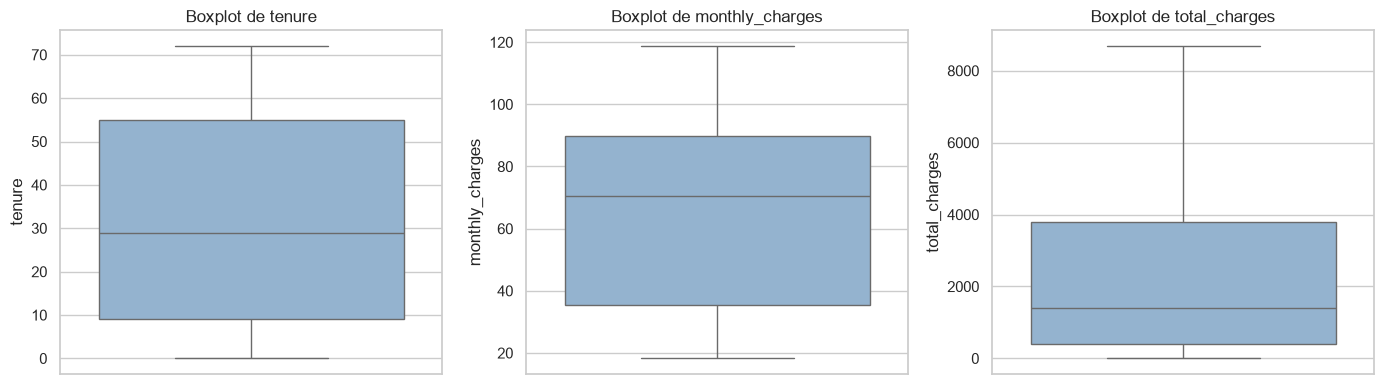

In [14]:
variables_numericas = ["tenure", "monthly_charges", "total_charges"]  # las tres variables cuantitativas originales
figura, ejes = plt.subplots(1, 3, figsize=(14, 4))  # crea una figura con 1 fila y 3 gráficos; devuelve la figura y la lista de ejes
for eje, columna in zip(ejes, variables_numericas):  # zip empareja cada eje con su variable (como recorrer dos listas en paralelo)
    sns.boxplot(y=df[columna], ax=eje, color="#8ab4d9")  # dibuja el boxplot de la columna en ese eje
    eje.set_title(f"Boxplot de {columna}")  # título del gráfico
plt.tight_layout()  # acomoda los gráficos para que no se superpongan
plt.show()  # muestra la figura

In [15]:
def resumen_iqr(serie):  # calcula los datos de la regla del IQR para una columna numérica
    q1 = serie.quantile(0.25)  # primer cuartil: valor que deja el 25 % de los datos por debajo
    q3 = serie.quantile(0.75)  # tercer cuartil: valor que deja el 75 % de los datos por debajo
    iqr = q3 - q1  # rango intercuartílico: ancho de la caja central
    limite_inferior = q1 - 1.5 * iqr  # valores por debajo de este límite son outliers
    limite_superior = q3 + 1.5 * iqr  # valores por encima de este límite son outliers
    es_outlier = (serie < limite_inferior) | (serie > limite_superior)  # máscara booleana; | es el OR elemento a elemento (en pandas no se usa 'or')
    return {  # devuelve un diccionario con todos los resultados
        "Q1": q1,  # primer cuartil
        "Q3": q3,  # tercer cuartil
        "IQR": iqr,  # rango intercuartílico
        "límite inferior": limite_inferior,  # cota inferior
        "límite superior": limite_superior,  # cota superior
        "mínimo": serie.min(),  # menor valor observado, para comparar con la cota inferior
        "máximo": serie.max(),  # mayor valor observado, para comparar con la cota superior
        "outliers": int(es_outlier.sum()),  # cantidad de valores fuera de los límites (int para que no quede como numpy.int64)
        "% outliers": round(100 * es_outlier.mean(), 2),  # porcentaje: la media de una máscara booleana es la proporción de True
    }  # cierra el diccionario


tabla_iqr = pd.DataFrame({col: resumen_iqr(df[col]) for col in variables_numericas}).T  # arma una columna por variable con una comprensión de diccionario y transpone (.T) para que cada variable sea una fila
display(tabla_iqr.round(2))  # muestra la tabla con 2 decimales

,Q1,Q3,IQR,límite inferior,límite superior,mínimo,máximo,outliers,% outliers
tenure,9.00,55.00,46.00,-60.00,124.00,0.00,72.00,0.0,0.0
monthly_charges,35.50,89.85,54.35,-46.02,171.38,18.25,118.75,0.0,0.0
total_charges,398.55,3786.60,3388.05,-4683.52,8868.67,0.00,8684.80,0.0,0.0


### Conclusión: se conservan todos los valores

La regla del IQR no detecta **ningún outlier** en `tenure`, `monthly_charges` ni `total_charges` (0 de 7043 en las tres). En cada variable el mínimo y el máximo observados caen dentro de los límites: los boxplots no muestran puntos aislados.

Por qué no hay que tratar nada:

- **`tenure` (0–72 meses):** el rango es el esperable para una base de clientes de unos 6 años; los extremos son clientes nuevos o muy antiguos, ambos legítimos y valiosos para el análisis de churn.
- **`monthly_charges` (≈ 18 a ≈ 119):** el rango es coherente con planes básicos hasta paquetes completos con fibra y streaming.
- **`total_charges` (0 a ≈ 8685):** es el acumulado de `tenure × cargo`, así que su máximo es consistente con el máximo de ambas variables. Tiene sesgo a la derecha (muchos clientes con poco acumulado), pero *asimetría no es lo mismo que outlier*: los valores altos son clientes antiguos con planes caros.

**Decisión:** conservar todas las filas, sin recortar ni winsorizar. Eliminar valores sin evidencia de error sería perder información real, y sin outliers no hay motivo para transformar la escala. Si Modelado usa un algoritmo sensible a la escala, el escalado queda de su lado.

## 8. Filtrado y agregación

Requisitos de la consigna: filtros con **múltiples condiciones** y `groupby` con **múltiples agregaciones**.

### 8.1 Filtros con `&` y `|`

En pandas se combinan condiciones con `&` (AND), `|` (OR) y `~` (NOT), **no** con `and`/`or`/`not`, y **cada condición va entre paréntesis** por la precedencia de los operadores. Un filtro es como un `WHERE` de SQL o un `.Where(...)` de LINQ.

Tres filtros con sentido de negocio:
1. **Fugas de alto valor:** clientes mes a mes con cargos mensuales en el cuartil más alto que se fueron. Son las bajas que más ingreso recurrente se llevan.
2. **Fuga pese al compromiso:** clientes con contrato de uno *o* dos años que igual se fueron. Son casos atípicos (el contrato debería retenerlos) y merecen una revisión del equipo comercial.
3. **Perfil de riesgo según las hipótesis:** clientes nuevos (hasta 12 meses), con fibra óptica y pago por electronic check. Se mide cuánta fuga tiene este perfil comparada con la base completa.

In [16]:
umbral_alto = df["monthly_charges"].quantile(0.75)  # cuartil 75: cargo mensual que supera el 75 % de los clientes (definición de "cargo alto")
total_churn = (df["churn"] == "Yes").sum()  # cantidad total de clientes que se fueron (base para calcular porcentajes)

filtro_fuga_alto_valor = (  # condición compuesta: se arma como una máscara booleana
    (df["contract"] == "Month-to-month")  # condición 1: contrato mes a mes
    & (df["monthly_charges"] >= umbral_alto)  # condición 2 (AND): cargo mensual alto
    & (df["churn"] == "Yes")  # condición 3 (AND): el cliente se fue
)  # cierra la condición compuesta
fuga_alto_valor = df[filtro_fuga_alto_valor]  # aplicar la máscara a df equivale a WHERE: devuelve solo las filas que cumplen
print(f"1) Fugas de alto valor (mes a mes, cargo >= {umbral_alto:.2f}): {len(fuga_alto_valor)} clientes = {len(fuga_alto_valor) / total_churn:.1%} de todas las fugas")  # len = cantidad de filas; :.1% formatea como porcentaje con 1 decimal
print(f"   Ingreso mensual recurrente perdido: {fuga_alto_valor['monthly_charges'].sum():,.2f}")  # suma de los cargos mensuales de esos clientes; :,.2f agrega separador de miles
display(fuga_alto_valor.head())  # muestra algunas filas del resultado

1) Fugas de alto valor (mes a mes, cargo >= 89.85): 456 clientes = 24.4% de todas las fugas
   Ingreso mensual recurrente perdido: 44,787.80


,gender,senior_citizen,partner,dependents,tenure,phone_service,multiple_lines,internet_service,online_security,online_backup,device_protection,tech_support,streaming_tv,streaming_movies,contract,paperless_billing,payment_method,monthly_charges,total_charges,avg_historical_charge,billing_gap,churn
5,Female,No,No,No,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.50,102.56,-23.30,Yes
8,Female,No,Yes,No,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,108.79,-111.65,Yes
13,Male,No,No,No,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.30,102.78,45.00,Yes
26,Male,No,Yes,Yes,47,Yes,Yes,Fiber optic,No,Yes,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.35,4749.15,101.05,-79.70,Yes
38,Male,No,No,No,34,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,106.35,3549.25,104.39,66.65,Yes


In [17]:
filtro_compromiso_fuga = (  # condición compuesta que mezcla OR y AND
    ((df["contract"] == "One year") | (df["contract"] == "Two year"))  # contrato de uno O dos años (el OR va entre paréntesis para que AND no lo "rompa")
    & (df["churn"] == "Yes")  # Y además se fue
)  # cierra la condición compuesta
compromiso_fuga = df[filtro_compromiso_fuga]  # aplica el filtro (WHERE)
equivalente = df[df["contract"].isin(["One year", "Two year"]) & (df["churn"] == "Yes")]  # isin equivale a SQL IN (...): misma lógica, más legible con muchos valores
assert len(compromiso_fuga) == len(equivalente)  # comprobamos que ambas formas de escribirlo dan lo mismo
print(f"2) Se fueron pese a tener contrato anual o bianual: {len(compromiso_fuga)} clientes = {len(compromiso_fuga) / total_churn:.1%} de todas las fugas")  # cantidad y porcentaje sobre el total de fugas
print("   Su antigüedad mediana (meses):", compromiso_fuga["tenure"].median())  # median() es la mediana, menos sensible a extremos que la media

perfil_riesgo = df[  # filtro con tres condiciones sobre columnas de tipos distintos
    (df["tenure"] <= 12)  # cliente nuevo (hasta un año)
    & (df["internet_service"] == "Fiber optic")  # con fibra óptica
    & (df["payment_method"] == "Electronic check")  # que paga con electronic check
]  # cierra el filtro
tasa_perfil = (perfil_riesgo["churn"] == "Yes").mean()  # la media de una máscara booleana es la proporción de True: tasa de churn del perfil
tasa_base = (df["churn"] == "Yes").mean()  # tasa de churn de toda la base, para comparar
print(f"3) Perfil nuevo + fibra + electronic check: {len(perfil_riesgo)} clientes | churn {tasa_perfil:.1%} vs {tasa_base:.1%} de la base")  # compara el perfil contra la base

2) Se fueron pese a tener contrato anual o bianual: 214 clientes = 11.4% de todas las fugas
   Su antigüedad mediana (meses): 53.0
3) Perfil nuevo + fibra + electronic check: 635 clientes | churn 70.9% vs 26.5% de la base


### 8.2 Agregaciones con `groupby` + `.agg`

`groupby` hace lo mismo que `GROUP BY` en SQL o `GroupBy` en LINQ: parte la tabla en grupos y calcula resúmenes por grupo. Con `.agg(nombre=("columna", "función"))` se piden **varias agregaciones a la vez** y se nombran los resultados.

La **tasa de churn** se obtiene convirtiendo `churn` a 0/1 en una columna auxiliar: la *media* de esa columna es la proporción de clientes que se fueron (equivale a `AVG(CASE WHEN churn = 'Yes' THEN 1 ELSE 0 END)`). Se resume por `contract` y por `payment_method`, que son las dos variables de H1 y H3.

> Esto es solo la tabla de resumen que pide la consigna. La interpretación y los gráficos corresponden a EDA.

In [18]:
base_agg = df.assign(churn_flag=(df["churn"] == "Yes").astype(int))  # assign devuelve una copia con una columna temporal churn_flag (1 = se fue, 0 = sigue); df queda sin tocar


def resumen_por(columna):  # función que resume la base agrupando por la columna indicada
    resumen = base_agg.groupby(columna, observed=True).agg(  # GROUP BY columna; observed=True ignora categorías sin filas (evita un warning con dtype category)
        clientes=("churn_flag", "count"),  # COUNT(*): cantidad de clientes del grupo
        clientes_que_se_fueron=("churn_flag", "sum"),  # SUM de la bandera: cuántos se fueron
        tasa_churn_pct=("churn_flag", "mean"),  # AVG de la bandera: proporción que se fue (se pasa a % abajo)
        cargo_mensual_promedio=("monthly_charges", "mean"),  # promedio del cargo mensual
        antiguedad_promedio_meses=("tenure", "mean"),  # promedio de antigüedad
        facturacion_total=("total_charges", "sum"),  # SUM de lo facturado acumulado
    )  # cierra agg: cada argumento nombre=(columna, función) crea una columna de salida
    resumen["tasa_churn_pct"] = (resumen["tasa_churn_pct"] * 100).round(1)  # pasa la proporción a porcentaje con 1 decimal
    resumen[["cargo_mensual_promedio", "antiguedad_promedio_meses"]] = resumen[["cargo_mensual_promedio", "antiguedad_promedio_meses"]].round(2)  # redondea los promedios a 2 decimales
    resumen["facturacion_total"] = resumen["facturacion_total"].round(2)  # redondea la suma de facturación
    return resumen.sort_values("tasa_churn_pct", ascending=False)  # ordena de mayor a menor tasa de churn (ORDER BY ... DESC)


print("Resumen por contract:")  # título
display(resumen_por("contract"))  # aplica la función a contract
print("Resumen por payment_method:")  # título
display(resumen_por("payment_method"))  # aplica la función a payment_method

Resumen por contract:


,clientes,clientes_que_se_fueron,tasa_churn_pct,cargo_mensual_promedio,antiguedad_promedio_meses,facturacion_total
contract,,,,,,
Month-to-month,3875,1655,42.7,66.40,18.04,5305861.5
One year,1473,166,11.3,65.05,42.04,4467053.5
Two year,1695,48,2.8,60.77,56.74,6283253.7


Resumen por payment_method:


,clientes,clientes_que_se_fueron,tasa_churn_pct,cargo_mensual_promedio,antiguedad_promedio_meses,facturacion_total
payment_method,,,,,,
Electronic check,2365,1071,45.3,76.26,25.17,4944903.25
Mailed check,1612,308,19.1,43.92,21.83,1691392.20
Bank transfer (automatic),1544,258,16.7,67.19,43.66,4748279.90
Credit card (automatic),1522,232,15.2,66.51,43.27,4671593.35
